# v5 - Hommerich (rio Geul, Paises Bajos): STIV metrico con camara calibrada

Mide la velocidad superficial y el **caudal** del rio Geul en Hommerich a partir del video
**original** de una camara fija oblicua, con el STIV de la v4. El dataset (una muestra de pyorc)
trae lo que faltaba en la v4: **intrinsecos, distorsion de lente y 6 puntos de control RTK**, la
lectura de la escala limnimetrica y una seccion transversal levantada. Con eso la pose de la camara
se resuelve entera y vuelve a haber **metros**, y con la seccion, **caudal**.

**Los datos de entrada se leen en modo solo lectura. Todo lo que este notebook genera se escribe en
`salidas/`.** Las lineas de codigo que cambian respecto a la v4 llevan la marca `# [v5]`.

---
## Que cambia respecto a v4

| Parte | v4 (Boneyard Creek) | v5 (Hommerich) | Por que lo obliga este caso |
|---|---|---|---|
| 0-1 | 61 videos, triaje y medida de vibracion | un video, su `cam_config` y su seccion | hay una sola grabacion de 4 s, de camara fija |
| 2 | punto de fuga + homografia, alturas de camara | **`solvePnP`** con 6 GCPs y la distorsion de lente; el plano rectificado es un **mapa** (`remap`) en metros | hay calibracion completa; la lente (k1 = -0.48) no la puede representar una homografia |
| 3 | estaciones repartidas a lo ancho | una estacion por **vertical de la seccion** (como en la v3) | vuelve a haber seccion levantada |
| 3 | `V_ESPERADA` por correlacion de fase | `V_ESPERADA` **a ojo**, 1.2 m/s (como en la v3) | en m/s si hay intuicion |
| 4 | rectificar con `warpPerspective(homografia)` | rectificar con `remap(mapa_rect)` | consecuencia de la fila 2 |
| 4 | `LADO_BLOQUE` = 64, `SIGMA_DERIVADA` = 0 | `LADO_BLOQUE` = **32**, `SIGMA_DERIVADA` = **1.5** | el video tiene 122 fotogramas: con 64 solo caben 4 bloques; el perfil tiene mucho contraste de velocidad, y sin suavizado las pendientes se comprimen hacia 1 (lo midio la v4 sobre el Sile) |
| 4b | `CONTRASTE_MIN` = 1.5 | `CONTRASTE_MIN` = **3.0** | una vertical de orilla quieta tiene contraste 2.3 y daria v ~ 0 con coherencia > 0.70 |
| 4b-5 | sin relleno ni caudal | **relleno lineal** con los ceros de las orillas como apoyo, e **integracion** del caudal | hay seccion; en un cauce natural la orilla en rampa es la hipotesis correcta (en la caja de la v3 no) |
| 5 | (sin caudal) | `V_CORR` = **0.85** | es el `v_corr` del propio `hommerich.yml` del dataset |
| 7 | diagnostico con el limnigrafo | sin referencia independiente | el dataset no trae aforo |

**Lo que no cambia:** la STI en una sola pasada con rectificacion previa, `DS` = desplazamiento por
fotograma y antialias `DS/2`, `mapa_lineas`, `preparar_sti`, el tensor con diferencias centrales,
`medir_sti`, `COH_MIN_BLOQUE` = 0.50, `COH_MIN_ESTACION` = 0.70, `N_FRAMES` = 250 (el video se
acaba antes) y el modulo `benchmark`.

---
## Parte 0 - Rutas de trabajo

Los datos del Geul estan en la carpeta de datasets externos (ver `datos/externos/LEEME.md`). Del
paquete se usan el video original, `cam_config_gcp1.json` (intrinsecos, distorsion, GCPs, `h_ref` y
`z_0`) y `cs1_ordered.geojson` (seccion). El ortomosaico que trae no se usa.

In [1]:
import os
from pathlib import Path

import benchmark  # modulo local (benchmark.py, en esta misma carpeta)


def buscar_datasets():
    """Carpeta 'datasets vision velocimetria', donde este."""
    candidatos = [Path("../../datos/externos/datasets vision velocimetria")]
    if os.environ.get("DATASETS_VELOCIMETRIA"):
        candidatos.append(Path(os.environ["DATASETS_VELOCIMETRIA"]))
    candidatos.append(Path("../../../test_pyorc-20261009T172625Z-1-001/test_pyorc/"
                           "datasets vision velocimetria"))
    for c in candidatos:
        if c.is_dir():
            return c
    raise SystemExit("No se encuentran los datasets externos: ver datos/externos/LEEME.md")


# --- Entradas (nunca se modifican) ---
DIR_DATOS = buscar_datasets() / "Hommerich"                                         # [v5]
DIR_PYORC = DIR_DATOS / "hommerich_20241010_081717_pyorc_data.zip"                  # [v5] carpeta
ARCHIVO_VIDEO = DIR_DATOS / "20241010_081717.mp4"                                   # [v5]
ARCHIVO_CAMCONF = DIR_PYORC / "cam_config_gcp1.json"                                # [v5]
ARCHIVO_SECCION = DIR_PYORC / "cs1_ordered.geojson"                                 # [v5]

# --- Salidas ---
DIR_SALIDA = Path("salidas")
# exist_ok=True evita el error si la carpeta ya existe de una ejecucion anterior.
DIR_SALIDA.mkdir(exist_ok=True)

SALIDA_CONFIG = DIR_SALIDA / "config.json"                 # configuracion congelada
SALIDA_PERFIL = DIR_SALIDA / "perfil_velocidades.csv"      # velocidad estacion por estacion
SALIDA_RESUMEN = DIR_SALIDA / "caudal_resumen.csv"         # [v5] tabla final
SALIDA_BENCHMARK = DIR_SALIDA / "benchmark_recursos.csv"   # coste de cada etapa

# Se vacian las mediciones por si el notebook se reejecuta sin reiniciar el kernel.
benchmark.reiniciar()

print("Datos de entrada:", DIR_DATOS)
print("Salidas en:      ", DIR_SALIDA)
# Se comprueba de una vez que las entradas existen, antes de procesar nada.
for entrada in (ARCHIVO_VIDEO, ARCHIVO_CAMCONF, ARCHIVO_SECCION):                   # [v5]
    print(f"  {'OK   ' if entrada.exists() else 'FALTA'} {entrada.name}")

Datos de entrada: ..\..\..\test_pyorc-20261009T172625Z-1-001\test_pyorc\datasets vision velocimetria\Hommerich
Salidas en:       salidas
  OK    20241010_081717.mp4
  OK    cam_config_gcp1.json
  OK    cs1_ordered.geojson


---
## Parte 1 - Lectura del video

Un solo video de 4 s, de camara fija: no hay triaje que hacer ni movimiento que corregir.

Dimensiones del fotograma: (1080, 1920, 3)
FPS del video: 29.8532  ->  DT = 33.497 ms
Fotogramas en el video: 122


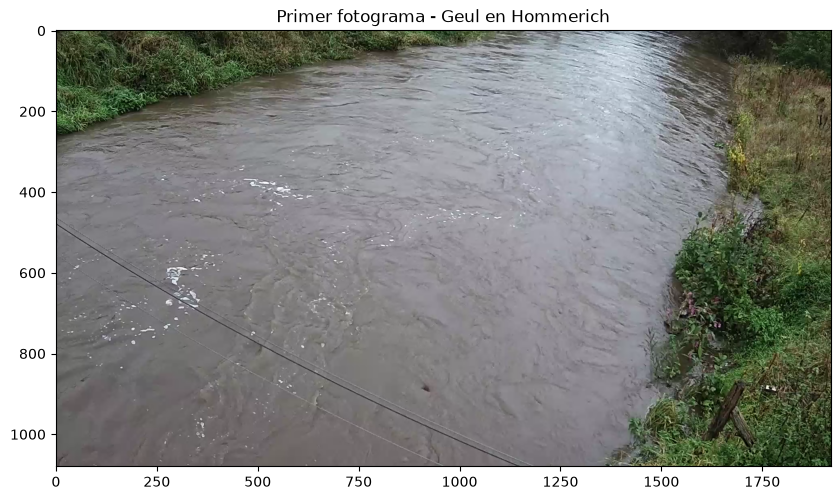

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# OpenCV: los metadatos y el primer fotograma del video que se mide.
cap = cv2.VideoCapture(str(ARCHIVO_VIDEO))
FPS = cap.get(cv2.CAP_PROP_FPS)
N_TOTAL = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
ok, frame_bgr = cap.read()
cap.release()
DT = 1.0 / FPS                    # intervalo entre fotogramas: entra en la velocidad
# OpenCV lee en BGR; matplotlib espera RGB.
frame = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

# Forma (filas, columnas, canales): las filas son la altura y las columnas el ancho.
print(f"Dimensiones del fotograma: {frame.shape}")
print(f"FPS del video: {FPS:.4f}  ->  DT = {DT * 1000:.3f} ms")
print(f"Fotogramas en el video: {N_TOTAL}")

plt.figure(figsize=(10, 6))
plt.imshow(frame)
plt.title("Primer fotograma - Geul en Hommerich")                                    # [v5]
plt.savefig(DIR_SALIDA / "fig1_fotograma.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 2 - Geometria: pose de la camara y plano rectificado en metros

1. **`solvePnP`** con los 6 GCPs (pixel <-> XYZ en EPSG:28992), los intrinsecos y la distorsion: da
   la pose completa. Se resuelve en coordenadas locales (restando el centroide de los GCPs) porque
   en coordenadas RD New absolutas (~3e5) la condicion numerica es mala, y con SQPNP porque los 6
   GCPs estan casi en un plano.
2. **La lamina de agua** es el plano `z = z_0 + (h_a - h_ref)`, con la lectura de escala `h_a` del
   propio script del dataset.
3. **La seccion** (24 puntos WGS84 con cota) se reproyecta a EPSG:28992 y se le ajusta una recta por
   PCA sobre los puntos mojados: su direccion es el eje transversal `u` y la perpendicular, la
   linea de flujo `v`. Las orillas se anaden donde la cota corta el nivel del agua.
4. **El plano rectificado** se construye en ese sistema (u, v) a 0.01 m/px. Cada punto se lleva a
   pixel con `projectPoints`, que **si** incluye la distorsion: por eso la rectificacion es un mapa
   punto a punto que se aplica con `remap`, y no la homografia de la v4.

Una decision del caso: **la seccion se mide 2.5 m aguas abajo** de donde se levanto. En su posicion
original las verticales de la orilla lejana se salen del encuadre; a 2.5 m entran todas enteras.
El precio es suponer el cauce prismatico en ese tramo (los calados son los levantados).

Reproyeccion de los 6 GCPs: mediana 0.56 px, maxima 2.50 px
Lamina de agua en z = 151.385 m
Seccion: 18 verticales (2 de orilla), ancho mojado 12.13 m, area 11.636 m2
Plano rectificado: 1333x620 px a 10 mm/px


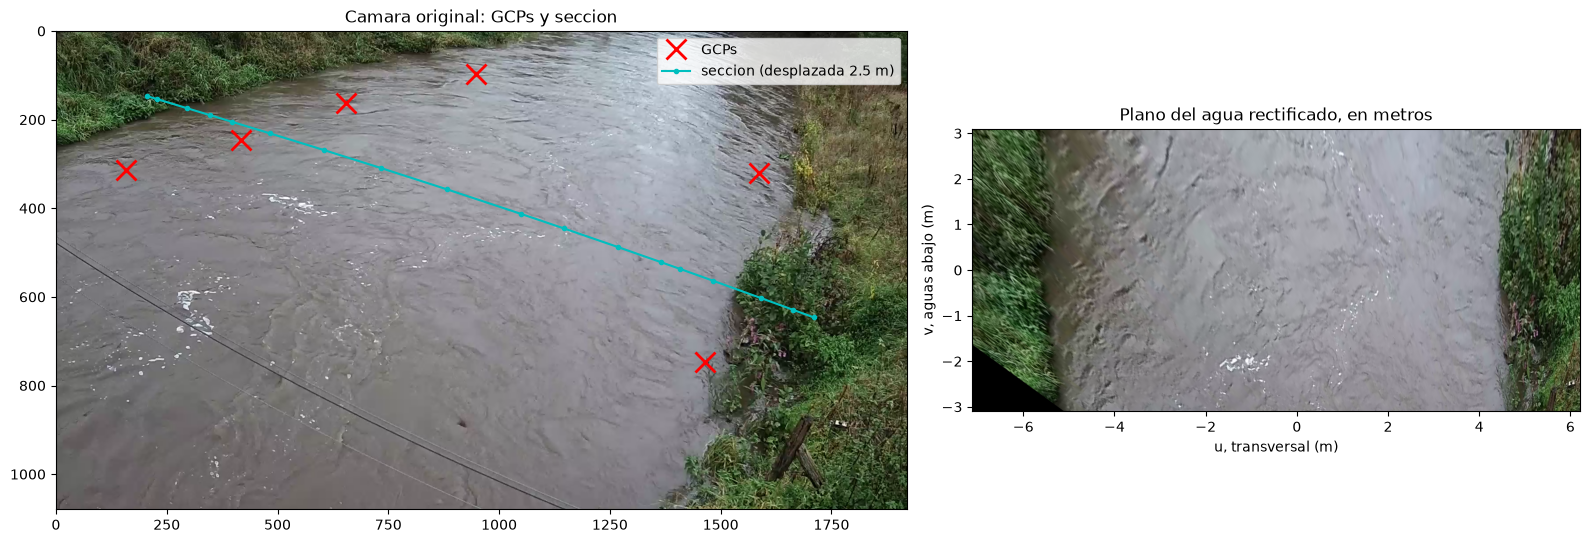

In [3]:
import json

import pyproj                                                                         # [v5]

# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Geometria                                                       [v5]
# ---------------------------------------------------------------------------------------
# Lectura de la escala en el momento del video, en la regla del limnimetro (es el --h_a
# del script process_20241010_081717_h_a.sh del dataset).  (obtenido del dataset)
H_A = 93.345
RESOLUCION = 0.01             # m/px del plano rectificado, la del cam_config del dataset
LARGO_LINEA = 5.0             # m de linea de busqueda: el agua recorre ~4.8 m en los 4 s
MARGEN_RASTER = 0.6           # m de aire alrededor de la seccion
DESPLAZAMIENTO_SECCION = 2.5  # m aguas abajo: minimo para que todas las verticales entren
# ---------------------------------------------------------------------------------------

# [v5] 1) Pose de la camara.
cfg = json.loads(ARCHIVO_CAMCONF.read_text(encoding="utf-8"))
K = np.array(cfg["camera_matrix"], float)
DIST = np.array(cfg["dist_coeffs"], float).reshape(-1, 1)
src = np.array(cfg["gcps"]["src"], float)
dst = np.array(cfg["gcps"]["dst"], float)
origen = dst.mean(axis=0)
obj = np.ascontiguousarray(dst - origen)
ok, rvec, tvec = cv2.solvePnP(obj, src, K, DIST, flags=cv2.SOLVEPNP_SQPNP)
rvec, tvec = cv2.solvePnPRefineLM(obj, src, K, DIST, rvec, tvec)
err_gcp = np.linalg.norm(cv2.projectPoints(obj, rvec, tvec, K, DIST)[0].reshape(-1, 2) - src, axis=1)


def mundo_a_pixel(pts_xy, z):
    """[v5] (N,2) en EPSG:28992 sobre el plano z -> (N,2) pixeles del video, con distorsion."""
    pts = np.column_stack([pts_xy[:, 0], pts_xy[:, 1], np.full(len(pts_xy), z)]) - origen
    return cv2.projectPoints(np.ascontiguousarray(pts), rvec, tvec, K, DIST)[0].reshape(-1, 2)


# [v5] 2) La lamina de agua: h_ref y h_a son lecturas de la misma escala.
Z_AGUA = float(cfg["gcps"]["z_0"]) + (H_A - float(cfg["gcps"]["h_ref"]))

# [v5] 3) La seccion, en el sistema (u transversal, v flujo).
gj = json.loads(ARCHIVO_SECCION.read_text(encoding="utf-8"))
lon, lat, z = np.array([f["geometry"]["coordinates"] for f in gj["features"]], float).T
x, y = pyproj.Transformer.from_crs("EPSG:4326", "EPSG:28992", always_xy=True).transform(lon, lat)
P = np.column_stack([x, y])
mojado = z < Z_AGUA
centro = P[mojado].mean(axis=0)
_, _, vt = np.linalg.svd(P[mojado] - centro)
e_u = vt[0] / np.linalg.norm(vt[0])
if np.dot(P[-1] - P[0], e_u) < 0:                # orientada como el fichero, izq -> der
    e_u = -e_u
e_v = np.array([-e_u[1], e_u[0]])                # normal: la linea de flujo
u = (P - centro) @ e_u
idx = np.where(mojado)[0]
bordes = []
for a, b in ((idx[0] - 1, idx[0]), (idx[-1] + 1, idx[-1])):
    f = (Z_AGUA - z[b]) / (z[a] - z[b])          # donde la cota corta el nivel del agua
    bordes.append(u[b] + f * (u[a] - u[b]))
s_transecto = np.concatenate([[bordes[0]], u[idx], [bordes[1]]])
prof_transecto = np.concatenate([[0.0], Z_AGUA - z[idx], [0.0]])
orden = np.argsort(s_transecto)
s_transecto, prof_transecto = s_transecto[orden], prof_transecto[orden]
N_VERTICALES = len(s_transecto)
ES_CONTORNO = prof_transecto == 0.0
AREA_SECCION = float(np.trapezoid(prof_transecto, s_transecto))
centro = centro + DESPLAZAMIENTO_SECCION * e_v   # la seccion se traslada aguas abajo

# [v5] 4) El plano rectificado: cada pixel (columna = u, fila = v) llevado a la imagen.
u0, u1 = s_transecto[0] - MARGEN_RASTER, s_transecto[-1] + MARGEN_RASTER
v1 = LARGO_LINEA / 2 + MARGEN_RASTER
TAM_RECT = (int(round((u1 - u0) / RESOLUCION)), int(round(2 * v1 / RESOLUCION)))
jj, ii = np.meshgrid(np.arange(TAM_RECT[0]), np.arange(TAM_RECT[1]))
U = u0 + (jj + 0.5) * RESOLUCION
V = v1 - (ii + 0.5) * RESOLUCION                 # fila 0 arriba = v maxima (aguas abajo)
XY = centro + U[..., None] * e_u + V[..., None] * e_v
px = mundo_a_pixel(XY.reshape(-1, 2), Z_AGUA).reshape(TAM_RECT[1], TAM_RECT[0], 2)
MAPA_RECT = (np.ascontiguousarray(px[..., 0], np.float32), np.ascontiguousarray(px[..., 1], np.float32))
ESCALA = RESOLUCION           # [v5] m por px del plano rectificado

print(f"Reproyeccion de los 6 GCPs: mediana {np.median(err_gcp):.2f} px, maxima {err_gcp.max():.2f} px")
print(f"Lamina de agua en z = {Z_AGUA:.3f} m")
print(f"Seccion: {N_VERTICALES} verticales (2 de orilla), ancho mojado "
      f"{s_transecto[-1] - s_transecto[0]:.2f} m, area {AREA_SECCION:.3f} m2")
print(f"Plano rectificado: {TAM_RECT[0]}x{TAM_RECT[1]} px a {RESOLUCION * 1000:.0f} mm/px")

rect0 = cv2.remap(frame_bgr, MAPA_RECT[0], MAPA_RECT[1], cv2.INTER_LINEAR)
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw=dict(width_ratios=[1.4, 1]))
ax[0].imshow(frame)
ax[0].plot(src[:, 0], src[:, 1], "rx", ms=14, mew=2, label="GCPs")
q = mundo_a_pixel(centro + np.outer(s_transecto, e_u), Z_AGUA)
ax[0].plot(q[:, 0], q[:, 1], "c.-", label="seccion (desplazada 2.5 m)")
ax[0].legend(); ax[0].set_title("Camara original: GCPs y seccion")
ax[1].imshow(cv2.cvtColor(rect0, cv2.COLOR_BGR2RGB), extent=[u0, u1, -v1, v1])
ax[1].set_xlabel("u, transversal (m)"); ax[1].set_ylabel("v, aguas abajo (m)")
ax[1].set_title("Plano del agua rectificado, en metros")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig2_geometria.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 3 - Lineas de busqueda

Como en la v3, **una linea por vertical de la seccion**; como en la v4, la linea es una **columna**
del plano rectificado, muestreada de abajo arriba (`ANGULO_FLUJO` = -90, aguas abajo hacia arriba).
Las dos verticales de orilla tienen calado cero: no se miden, se les impone v = 0.

`V_ESPERADA` vuelve a ser una estimacion **a ojo** en m/s, como en la v3.

Desplazamiento esperado: 4.02 px/fotograma -> DS = 4 px, sigma antialias = 2.0 px, estelas a 45.1 grados
18 lineas de 125 muestras (5.00 m cada una)


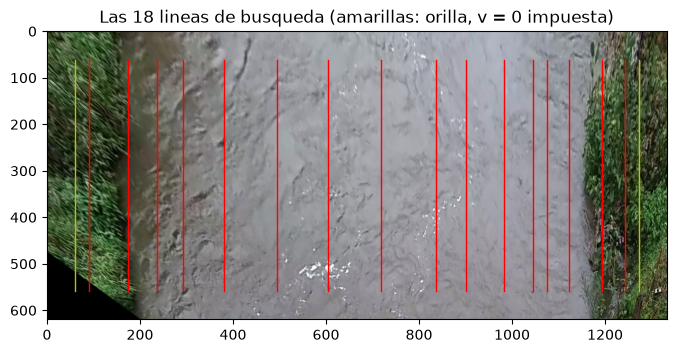

In [4]:
import pandas as pd

# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Lineas de busqueda
# ---------------------------------------------------------------------------------------
# Direccion del flujo en el plano rectificado: hacia arriba (+v, aguas abajo).
ANGULO_FLUJO = -90.0          # grados
# Orden de magnitud de la velocidad superficial, a ojo: de aqui sale el paso de muestreo.
V_ESPERADA = 1.2              # m/s   [v5]
# ---------------------------------------------------------------------------------------

# [v5] Estaciones: la columna de cada vertical de la seccion, centrada en la seccion.
centros = np.column_stack([(s_transecto - u0) / RESOLUCION, np.full(N_VERTICALES, TAM_RECT[1] / 2)])
D_ESPERADO = V_ESPERADA * DT / ESCALA        # px por fotograma
DS = int(round(D_ESPERADO))                  # paso de muestreo: estelas a ~45 grados
SIGMA_ANTIALIAS = 0.5 * DS                   # filtro paso bajo obligatorio antes de submuestrear
print(f"Desplazamiento esperado: {D_ESPERADO:.2f} px/fotograma -> DS = {DS} px, "
      f"sigma antialias = {SIGMA_ANTIALIAS:.1f} px, estelas a "
      f"{np.degrees(np.arctan(D_ESPERADO / DS)):.1f} grados")


def mapa_lineas(centros, angulos_deg, ds, largo):
    """Coordenadas de muestreo de cada linea: mapx, mapy de forma (n_lineas, n_muestras).

    Cada linea tiene su centro (x, y) y su largo en px.
    """
    centros = np.atleast_2d(np.asarray(centros, float))
    angs = np.radians(np.broadcast_to(np.asarray(angulos_deg, float), (len(centros),)))
    n_mu = int(largo / ds)
    # t recorre la linea centrada en su punto medio, en pixeles
    t = (np.arange(n_mu) - (n_mu - 1) / 2) * ds
    mapx = np.zeros((len(centros), n_mu), np.float32)
    mapy = np.zeros((len(centros), n_mu), np.float32)
    for i, ((cx, cy), a) in enumerate(zip(centros, angs)):
        mapx[i] = cx + t * np.cos(a)
        mapy[i] = cy + t * np.sin(a)
    return mapx, mapy


mapx, mapy = mapa_lineas(centros, ANGULO_FLUJO, DS, LARGO_LINEA / RESOLUCION)       # [v5]
print(f"{mapx.shape[0]} lineas de {mapx.shape[1]} muestras "
      f"({mapx.shape[1] * DS * ESCALA:.2f} m cada una)")

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(rect0, cv2.COLOR_BGR2RGB))                                  # [v5]
for i in range(N_VERTICALES):
    plt.plot(mapx[i], mapy[i], "y-" if ES_CONTORNO[i] else "r-", lw=1)
plt.title(f"Las {N_VERTICALES} lineas de busqueda (amarillas: orilla, v = 0 impuesta)")
plt.savefig(DIR_SALIDA / "fig3_lineas_busqueda.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 4 - Velocidades superficiales con STIV

El proceso de la v4, con la rectificacion por mapa (`remap`) en vez de por homografia. Dos
parametros del estimador cambian, y los dos por el caso:

- **`LADO_BLOQUE` = 32.** El video tiene 122 fotogramas: con bloques de 64 y 50 % de solape solo
  caben dos a lo largo del tiempo y dos a lo largo de la linea, cuatro en total, y la mediana
  ponderada deja de serlo. Con 32 caben 36.
- **`SIGMA_DERIVADA` = 1.5**, el de la v3. El 0 de la v4 era propio de la espuma fina de Boneyard,
  donde ademas toda la seccion iba a la misma velocidad. Aqui el perfil va de 0.7 a casi 2 m/s, y la
  v4 midio sobre el Sile que sin suavizado las pendientes lejos de 45 grados se comprimen hacia 1.

In [5]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Cuanto video se procesa y parametros del estimador
# ---------------------------------------------------------------------------------------
# Fotogramas a procesar. El video de Hommerich tiene 122 (4.1 s): se lee entero.
N_FRAMES = 250
# [v5] Lado del bloque de STI: 32 y no 64, porque el video solo tiene 122 fotogramas.
LADO_BLOQUE = 32
# Coherencia minima para que un bloque entre en la mediana ponderada.
COH_MIN_BLOQUE = 0.50
# [v5] Suavizado gaussiano previo a las derivadas, en pixeles de STI: el de la v3.
SIGMA_DERIVADA = 1.5
# ---------------------------------------------------------------------------------------


def construir_sti(archivo, mapx, mapy, n_frames, sigma, mapa_rect=None):
    """Apila n_frames filas muestreadas -> STI de forma (n_lineas, n_frames, n_muestras).

    [v5] Si se da un mapa de rectificacion (mapx, mapy del plano a la imagen), cada fotograma
    se rectifica con remap antes del antialias.
    """
    cap = cv2.VideoCapture(str(archivo))
    sti = np.zeros((mapx.shape[0], n_frames, mapx.shape[1]), np.float32)
    for k in range(n_frames):
        ok, fr = cap.read()
        if not ok:
            sti = sti[:, :k, :]
            break
        gris = cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY).astype(np.float32)
        if mapa_rect is not None:                                                    # [v5]
            gris = cv2.remap(gris, mapa_rect[0], mapa_rect[1], cv2.INTER_LINEAR)
        # Antialias ANTES de muestrear: sin esto el submuestreo inventa orientaciones.
        gris = cv2.GaussianBlur(gris, (0, 0), sigma)
        sti[:, k, :] = cv2.remap(gris, mapx, mapy, cv2.INTER_LINEAR)
    cap.release()
    return sti


def preparar_sti(sti):
    """Quita el fondo estatico y el parpadeo global, y normaliza."""
    a = sti - sti.mean(axis=0, keepdims=True)   # fondo fijo de cada muestra (rayas verticales)
    a = a - a.mean(axis=1, keepdims=True)       # parpadeo de cada fotograma (rayas horizontales)
    d = a.std()
    return a / d if d > 0 else a


def tensor_estructura(bloque, sigma=SIGMA_DERIVADA):
    """Pendiente m (muestras/fotograma) y coherencia C de un trozo de STI."""
    # Gaussiana opcional y diferencias centrales.
    g = cv2.GaussianBlur(bloque, (0, 0), sigma) if sigma > 0 else bloque
    # eje 0 = tiempo (filas), eje 1 = espacio (columnas)
    It, Ix = np.gradient(g)
    Jxx = float((Ix * Ix).sum())
    Jtt = float((It * It).sum())
    Jxt = float((Ix * It).sum())
    if Jxx + Jtt <= 0:
        return np.nan, 0.0
    # autovector del autovalor MENOR = direccion a lo largo de las estelas
    _, vec = np.linalg.eigh(np.array([[Jxx, Jxt], [Jxt, Jtt]]))
    ex, et = vec[:, 0]
    if et < 0:            # el autovector esta definido salvo signo: se orienta hacia t creciente
        ex, et = -ex, -et
    m = ex / et if et != 0 else np.nan
    coherencia = np.sqrt((Jxx - Jtt) ** 2 + 4 * Jxt ** 2) / (Jxx + Jtt)
    return m, float(coherencia)


def medir_sti(sti_p, lado=LADO_BLOQUE, coh_min=COH_MIN_BLOQUE, sigma=SIGMA_DERIVADA):
    """Pendiente robusta de una STI, por bloques con solape: (m, coherencia mediana)."""
    nt, nx = sti_p.shape
    paso = lado // 2
    ms, cs = [], []
    for t0 in range(0, nt - lado + 1, paso):
        for x0 in range(0, nx - lado + 1, paso):
            m, c = tensor_estructura(sti_p[t0:t0 + lado, x0:x0 + lado], sigma)
            if np.isfinite(m):
                ms.append(m); cs.append(c)
    if not ms:
        return np.nan, 0.0
    ms, cs = np.array(ms), np.array(cs)
    coh_mediana = float(np.median(cs))
    usables = cs >= coh_min
    if usables.sum() == 0:
        return np.nan, coh_mediana
    # mediana ponderada por coherencia: los bloques nitidos pesan mas
    mm, cc = ms[usables], cs[usables]
    orden = np.argsort(mm)
    mm, cc = mm[orden], cc[orden]
    acumulado = np.cumsum(cc) / cc.sum()
    return float(mm[np.searchsorted(acumulado, 0.5)]), coh_mediana


# Unica pasada sobre el video: el bloque caro del notebook.
with benchmark.medir("Parte 4: construir las STI", n_frames=N_TOTAL):
    sti_crudo = construir_sti(ARCHIVO_VIDEO, mapx, mapy, N_FRAMES, SIGMA_ANTIALIAS,
                              MAPA_RECT)                                             # [v5]
np.save(DIR_SALIDA / "sti_crudo.npy", sti_crudo)
# Contraste temporal de cada estacion, antes de normalizar: lo usa la Parte 4b.
CONTRASTE = np.median(sti_crudo.std(axis=1), axis=1)

with benchmark.medir("Parte 4: preparar STI + tensor de estructura"):
    sti_prep = np.stack([preparar_sti(s) for s in sti_crudo])
    v_stiv = np.full(N_VERTICALES, np.nan)
    coherencia = np.full(N_VERTICALES, np.nan)
    for i in range(N_VERTICALES):
        if ES_CONTORNO[i]:                                                           # [v5]
            v_stiv[i] = 0.0           # condicion de contorno: calado nulo en la orilla
            continue
        m, coherencia[i] = medir_sti(sti_prep[i])
        v_stiv[i] = m * DS * ESCALA / DT if np.isfinite(m) else np.nan

print(f"STI: {sti_crudo.shape[0]} lineas x {sti_crudo.shape[1]} fotogramas x "
      f"{sti_crudo.shape[2]} muestras")
print(pd.DataFrame({"vertical": np.arange(N_VERTICALES), "s_m": s_transecto,
                    "calado_m": prof_transecto, "contraste": CONTRASTE,
                    "coherencia": coherencia, "v_ms": v_stiv})                       # [v5]
      .to_string(index=False, float_format=lambda x: f"{x:8.4f}"))

  [bench] Parte 4: construir las STI: 6.4 s | CPU 20.2 s (3.1 nucleos) | RAM pico 393 MB


  [bench] Parte 4: preparar STI + tensor de estructura: 0.2 s | CPU 0.2 s (1.0 nucleos) | RAM pico 254 MB
STI: 18 lineas x 122 fotogramas x 125 muestras
 vertical      s_m  calado_m  contraste  coherencia     v_ms
        0  -6.5198    0.0000     0.3737         NaN   0.0000
        1  -6.2052    0.2140     0.7539      0.8491   0.0425
        2  -5.3669    0.4260     2.3397      0.7843   0.0140
        3  -4.7588    0.6960    11.8088      0.7757   0.7051
        4  -4.1942    1.1700    13.3634      0.8182   0.8899
        5  -3.3078    1.1580     8.7753      0.6987   1.1779
        6  -2.1696    1.1810     5.3967      0.7308   1.4433
        7  -1.0871    1.2370     8.2224      0.7932   1.8005
        8   0.0564    1.2040     8.2655      0.7433   1.8739
        9   1.2537    1.2710     5.8856      0.7456   1.6157
       10   1.8976    1.2450     4.7566      0.8112   1.5538
       11   2.7117    1.2890     3.3060      0.7691   1.3386
       12   3.3399    1.1780     4.7502      0.8149   

---
## Parte 4b - Control de calidad y relleno

Los mismos dos criterios de la v4. El de **contraste temporal** sube a 3.0 por los datos: medido
sobre estas STI hay un hueco entre las verticales de orilla, sin trazador (hasta ~2.3), y las de
agua (desde ~3.3). Con el 1.5 de la v4 pasaria una vertical de orilla casi quieta con coherencia
alta: la misma trampa del cero estatico que la v4 descubrio en los muros de Boneyard.

**Vuelve el relleno**, porque vuelve a haber un caudal que integrar, y cambia una regla respecto a la
v3: alli los ceros de los muros **no** servian de apoyo, porque la caja de hormigon tiene muros
verticales y la velocidad se mantiene alta hasta muy cerca. En un **cauce natural** la orilla sube en
rampa y la velocidad cae hacia ella: aqui los ceros de las orillas **si** entran como apoyo.

In [6]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Criterios de aceptacion
# ---------------------------------------------------------------------------------------
# Coherencia mediana minima para dar por buena una estacion. La misma de la v3 y la v4.
COH_MIN_ESTACION = 0.70
# [v5] Desviacion temporal minima de la STI cruda: hueco medido entre orilla (<= 2.3) y agua
# (>= 3.3) en este video.
CONTRASTE_MIN = 3.0
# ---------------------------------------------------------------------------------------

with benchmark.medir("Parte 4b: control de calidad y relleno"):
    es_estatica = CONTRASTE < CONTRASTE_MIN
    medida = (~ES_CONTORNO) & (~es_estatica) & (coherencia >= COH_MIN_ESTACION) & np.isfinite(v_stiv)  # [v5]
    # [v5] Relleno lineal entre las medidas y los ceros de las orillas (cauce natural).
    apoyo = medida | ES_CONTORNO
    v_eff = np.where(apoyo, v_stiv, np.nan)
    rellenadas = np.where(~apoyo)[0]
    v_eff[rellenadas] = np.interp(s_transecto[rellenadas], s_transecto[apoyo], v_stiv[apoyo])
v_eff_medida = np.where(medida, v_stiv, np.nan)

print(f"Verticales medidas: {int(medida.sum())} de {int((~ES_CONTORNO).sum())} interiores")
for i in rellenadas:
    motivo = "contraste %.2f" % CONTRASTE[i] if es_estatica[i] else "coherencia %.2f" % coherencia[i]
    print(f"  vertical {i} (s = {s_transecto[i]:+.2f} m, calado {prof_transecto[i]:.2f} m, "
          f"{motivo}): {v_stiv[i]:.3f} -> {v_eff[i]:.3f} m/s [interpolada]")

  [bench] Parte 4b: control de calidad y relleno: 0.0 s | CPU 0.0 s (0.0 nucleos) | RAM pico 255 MB
Verticales medidas: 12 de 16 interiores
  vertical 1 (s = -6.21 m, calado 0.21 m, contraste 0.75): 0.043 -> 0.126 m/s [interpolada]
  vertical 2 (s = -5.37 m, calado 0.43 m, contraste 2.34): 0.014 -> 0.462 m/s [interpolada]
  vertical 5 (s = -3.31 m, calado 1.16 m, coherencia 0.70): 1.178 -> 1.132 m/s [interpolada]
  vertical 16 (s = +5.30 m, calado 0.25 m, contraste 1.23): -0.035 -> -0.005 m/s [interpolada]


---
## Parte 5 - Caudal sobre la seccion

La integracion de la v3: $q_i = V_{CORR}\,u_i\,h_i$ por trapecios sobre las verticales. `V_CORR` es
**0.85**, el `v_corr` que el propio dataset usa en su `hommerich.yml` (y el estandar del USGS),
fijado antes de mirar nada.

  [bench] Parte 5: integracion del caudal: 0.0 s | CPU 0.0 s (0.0 nucleos) | RAM pico 255 MB


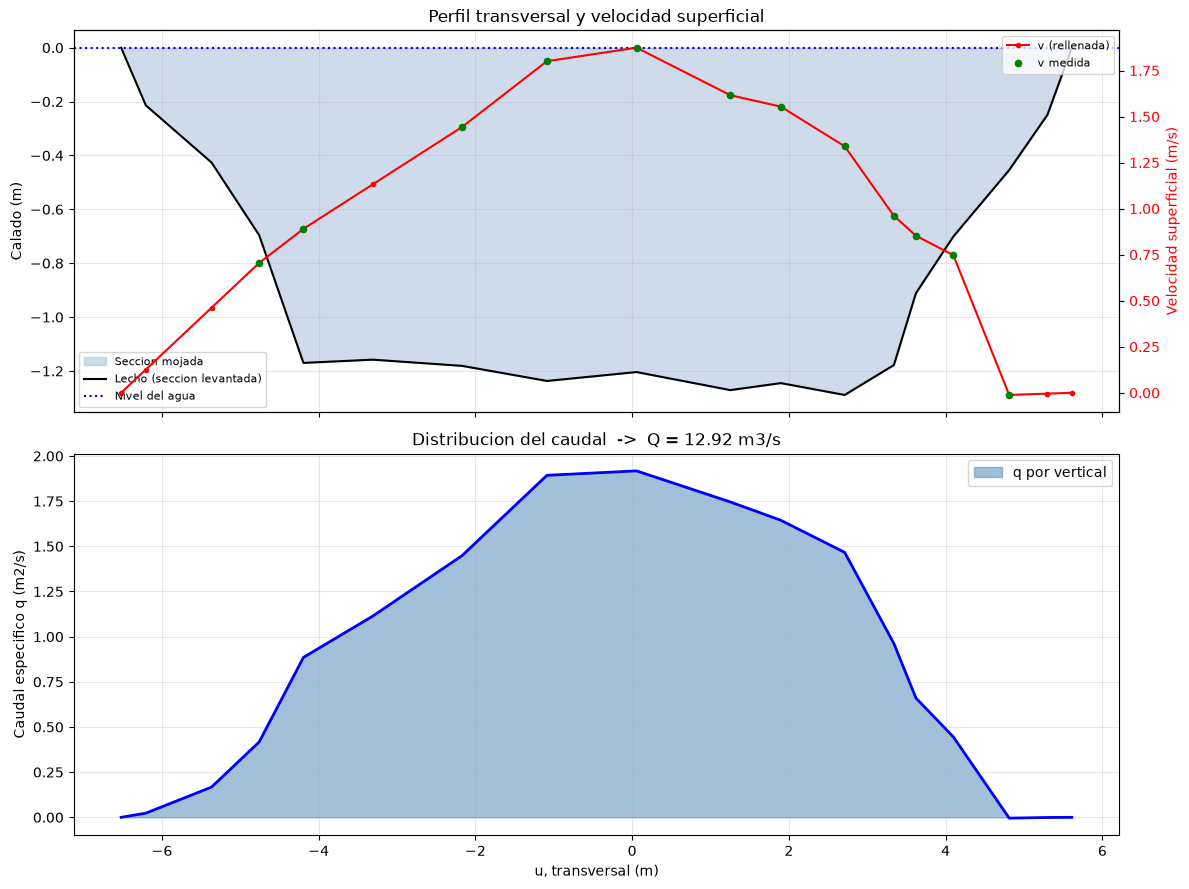

In [7]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Paso de velocidad superficial a media en la vertical
# ---------------------------------------------------------------------------------------
V_CORR = 0.85                 # [v5] el v_corr del hommerich.yml del dataset
# ---------------------------------------------------------------------------------------

with benchmark.medir("Parte 5: integracion del caudal"):                           # [v5]
    q_especifico = V_CORR * v_eff * prof_transecto                # m2/s
    Q_VIDEO = float(np.trapezoid(q_especifico, s_transecto))      # m3/s

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
ax_z = axes[0]
ax_z.fill_between(s_transecto, -prof_transecto, 0, color="lightsteelblue", alpha=0.6,
                  label="Seccion mojada")
ax_z.plot(s_transecto, -prof_transecto, "k-", lw=1.5, label="Lecho (seccion levantada)")
ax_z.axhline(0, color="b", ls=":", lw=1.5, label="Nivel del agua")
ax_z.set_ylabel("Calado (m)")
ax_z.set_title("Perfil transversal y velocidad superficial")
ax_z.legend(loc="lower left", fontsize=8)
ax_z.grid(True, alpha=0.3)
ax_v = ax_z.twinx()
ax_v.plot(s_transecto, v_eff, "r-o", ms=3, lw=1.5, label="v (rellenada)")
ax_v.plot(s_transecto, v_eff_medida, "g.", ms=9, label="v medida")
ax_v.set_ylabel("Velocidad superficial (m/s)", color="r")
ax_v.tick_params(axis="y", labelcolor="r")
ax_v.legend(loc="upper right", fontsize=8)
axes[1].fill_between(s_transecto, q_especifico, alpha=0.5, color="steelblue", label="q por vertical")
axes[1].plot(s_transecto, q_especifico, "b-", lw=2)
axes[1].set_xlabel("u, transversal (m)")
axes[1].set_ylabel("Caudal especifico q (m2/s)")
axes[1].set_title(f"Distribucion del caudal  ->  Q = {Q_VIDEO:.2f} m3/s")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig4_perfil_transecto.png", dpi=110, bbox_inches="tight")
plt.show()

In [8]:
print("=" * 52)
print(f"Caudal:          {Q_VIDEO:.3f} m3/s")
print(f"Velocidad media: {Q_VIDEO / AREA_SECCION:.4f} m/s")
print(f"Velocidad superficial mediana: {np.nanmedian(v_eff[~ES_CONTORNO]):.4f} m/s")
print(f"Verticales con velocidad medida: {int(medida.sum())} de "
      f"{int((~ES_CONTORNO).sum())} interiores (el resto, interpolacion lineal)")
print("=" * 52)

perfil = pd.DataFrame({
    "vertical": np.arange(N_VERTICALES),
    "s_m": s_transecto,
    "prof_m": prof_transecto,
    "contraste": CONTRASTE,
    "coherencia": coherencia,
    "v_sup_medida_ms": v_eff_medida,
    "v_sup_usada_ms": v_eff,
    "q_especifico_m2s": q_especifico,
    "origen": np.where(ES_CONTORNO, "orilla (v=0)",
                       np.where(medida, "medida", "relleno interpolacion lineal")),
})
perfil.to_csv(SALIDA_PERFIL, index=False)

config = dict(video=ARCHIVO_VIDEO.name, n_frames=int(sti_crudo.shape[1]), fps=FPS, h_a=H_A,
              z_agua=Z_AGUA, resolucion=RESOLUCION, largo_linea=LARGO_LINEA,
              desplazamiento_seccion=DESPLAZAMIENTO_SECCION, angulo_flujo=ANGULO_FLUJO,
              v_esperada=V_ESPERADA, ds_px=DS, sigma_antialias=SIGMA_ANTIALIAS,
              lado_bloque=LADO_BLOQUE, coh_min_bloque=COH_MIN_BLOQUE,
              sigma_derivada=SIGMA_DERIVADA, coh_min_estacion=COH_MIN_ESTACION,
              contraste_min=CONTRASTE_MIN, v_corr=V_CORR, area_m2=AREA_SECCION,
              caudal_m3s=Q_VIDEO)
SALIDA_CONFIG.write_text(json.dumps(config, indent=2), encoding="utf-8")
perfil

Caudal:          12.922 m3/s
Velocidad media: 1.1106 m/s
Velocidad superficial mediana: 0.9253 m/s
Verticales con velocidad medida: 12 de 16 interiores (el resto, interpolacion lineal)


,vertical,s_m,prof_m,contraste,coherencia,v_sup_medida_ms,v_sup_usada_ms,q_especifico_m2s,origen
0,0,-6.519850,0.000,0.373701,NaN,NaN,0.000000,0.000000,orilla (v=0)
1,1,-6.205165,0.214,0.753858,0.849070,NaN,0.126006,0.022921,relleno interpolacion lineal
2,2,-5.366871,0.426,2.339674,0.784321,NaN,0.461677,0.167173,relleno interpolacion lineal
3,3,-4.758847,0.696,11.808755,0.775744,0.705143,0.705143,0.417162,medida
4,4,-4.194195,1.170,13.363383,0.818241,0.889916,0.889916,0.885021,medida
5,5,-3.307822,1.158,8.775319,0.698685,NaN,1.132194,1.114418,relleno interpolacion lineal
6,6,-2.169638,1.181,5.396680,0.730833,1.443301,1.443301,1.448857,medida
7,7,-1.087104,1.237,8.222357,0.793217,1.800497,1.800497,1.893132,medida
8,8,0.056437,1.204,8.265496,0.743261,1.873870,1.873870,1.917719,medida
9,9,1.253732,1.271,5.885598,0.745615,1.615741,1.615741,1.745565,medida


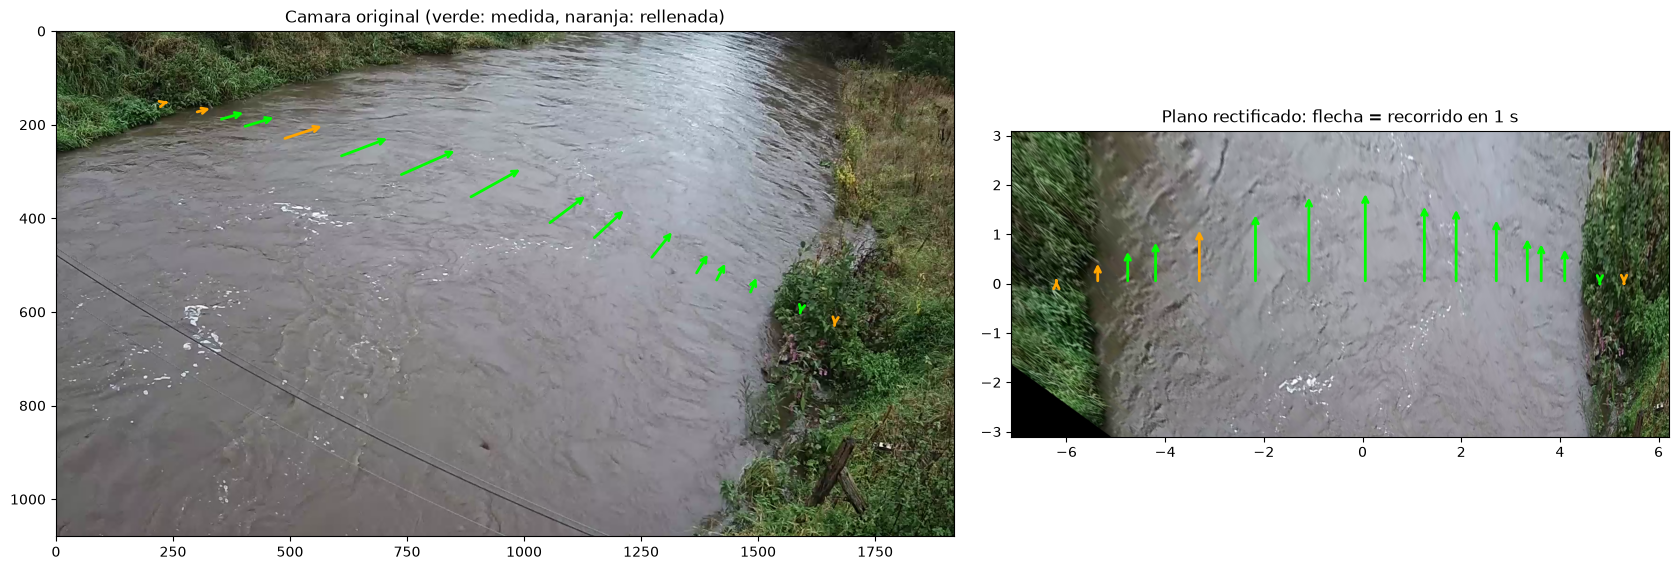

In [9]:
# [v5] Las velocidades sobre las dos vistas: la flecha mide lo que el agua recorre en 1 s, una
# longitud del mundo; en la camara original la perspectiva la acorta sola al proyectar su punta.
fig, ax = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw=dict(width_ratios=[1.4, 1]))
ax[0].imshow(frame)
ax[1].imshow(cv2.cvtColor(rect0, cv2.COLOR_BGR2RGB), extent=[u0, u1, -v1, v1])
for i in np.where(~ES_CONTORNO)[0]:
    base = centro + s_transecto[i] * e_u
    punta = base + v_eff[i] * 1.0 * e_v
    b, p = mundo_a_pixel(np.array([base, punta]), Z_AGUA)
    color = "lime" if medida[i] else "orange"
    ax[0].annotate("", p, b, arrowprops=dict(arrowstyle="->", color=color, lw=2))
    ax[1].annotate("", (s_transecto[i], v_eff[i]), (s_transecto[i], 0),
                   arrowprops=dict(arrowstyle="->", color=color, lw=2))
ax[0].set_title("Camara original (verde: medida, naranja: rellenada)")
ax[1].set_title("Plano rectificado: flecha = recorrido en 1 s")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig5_mapa_velocidades.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 6 - Recursos consumidos

Columnas: **segundos** de reloj; **cpu_s** y **nucleos**; **ram_pico_mb**, el maximo de memoria
residente durante la etapa; y **ram_neta_mb**.

Maquina donde se han medido los tiempos:
  cpu_nucleos_fisicos: 12
  cpu_nucleos_logicos: 16
  ram_total_gb: 42.7
  ram_disponible_gb: 19.8

Tiempo total medido: 6.6 s
Pico de memoria del proceso: 393 MB


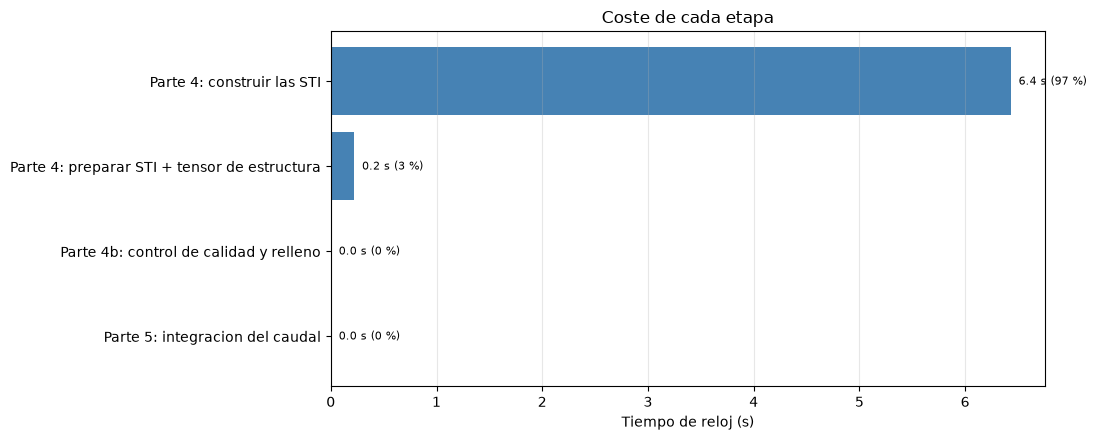

,etapa,segundos,cpu_s,nucleos,ram_pico_mb,ram_neta_mb,n_frames,pct_tiempo
0,Parte 4: construir las STI,6.43,20.23,3.15,393.4,2.5,122.0,96.7
1,Parte 4: preparar STI + tensor de estructura,0.22,0.22,1.00,254.2,1.2,NaN,3.3
2,Parte 4b: control de calidad y relleno,0.00,0.00,0.00,254.5,0.0,NaN,0.0
3,Parte 5: integracion del caudal,0.00,0.00,0.00,254.5,0.0,NaN,0.0


In [10]:
print("Maquina donde se han medido los tiempos:")
for k, v in benchmark.entorno().items():
    print(f"  {k}: {v}")

tabla_recursos = benchmark.tabla()
tabla_recursos.to_csv(SALIDA_BENCHMARK, index=False)
print(f"\nTiempo total medido: {tabla_recursos['segundos'].sum():.1f} s")
print(f"Pico de memoria del proceso: {tabla_recursos['ram_pico_mb'].max():.0f} MB")

fig, ax = plt.subplots(figsize=(11, 4.5))
orden = tabla_recursos.sort_values("segundos")
ax.barh(orden["etapa"], orden["segundos"], color="steelblue")
ax.set_xlabel("Tiempo de reloj (s)")
ax.set_title("Coste de cada etapa")
ax.grid(axis="x", alpha=0.3)
for y, (seg, pct) in enumerate(zip(orden["segundos"], orden["pct_tiempo"])):
    ax.text(seg, y, f"  {seg:.1f} s ({pct:.0f} %)", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig6_recursos.png", dpi=110, bbox_inches="tight")
plt.show()
tabla_recursos

---
## Parte 7 - Referencia

**No hay referencia independiente.** El paquete del dataset trae la configuracion y el log del
proceso que hicieron sus autores con pyorc, pero no el caudal que obtuvieron ni ningun aforo. El
caudal de esta version no esta contrastado contra nada: para cerrarlo habria que ejecutar pyorc con
el `cam_config`, el `hommerich.yml` y la seccion del propio dataset, y entonces seria una
comparacion LSPIV-STIV como la de v2-v3.

Lo unico que se puede poner al lado es el resultado del caso original, que **no es una referencia**
(es el mismo metodo con otra configuracion: ventanas moviles de 2.4 s con bloques de 32 y la mediana
de las ventanas).

In [11]:
# [v5] Parte nueva: no hay referencia; se anota el caso original solo como contexto.
Q_CASO_ORIGINAL = 13.68       # m3/s, casos/05_hommerich_stiv (mediana de 26 ventanas de 2.4 s)
print(f"Caudal de esta version:          {Q_VIDEO:.2f} m3/s  (los 4.1 s de golpe)")
print(f"Caudal del caso original (STIV): {Q_CASO_ORIGINAL:.2f} m3/s  "
      f"({100 * (Q_VIDEO / Q_CASO_ORIGINAL - 1):+.1f} %), no es una referencia")

resumen = pd.DataFrame([
    dict(concepto="Caudal (este notebook)", valor=Q_VIDEO, unidad="m3/s"),
    dict(concepto="Area de la seccion", valor=AREA_SECCION, unidad="m2"),
    dict(concepto="Velocidad media", valor=Q_VIDEO / AREA_SECCION, unidad="m/s"),
    dict(concepto="Verticales medidas", valor=int(medida.sum()), unidad=f"de {int((~ES_CONTORNO).sum())}"),
    dict(concepto="V_CORR usado", valor=V_CORR, unidad="-"),
    dict(concepto="Caudal del caso original (contexto, no referencia)", valor=Q_CASO_ORIGINAL,
         unidad="m3/s"),
])
resumen.to_csv(SALIDA_RESUMEN, index=False)
resumen

Caudal de esta version:          12.92 m3/s  (los 4.1 s de golpe)
Caudal del caso original (STIV): 13.68 m3/s  (-5.5 %), no es una referencia


,concepto,valor,unidad
0,Caudal (este notebook),12.922294,m3/s
1,Area de la seccion,11.635612,m2
2,Velocidad media,1.110581,m/s
3,Verticales medidas,12.000000,de 16
4,V_CORR usado,0.850000,-
5,"Caudal del caso original (contexto, no referen...",13.680000,m3/s


---
## Archivos generados

Todo queda en `salidas/`, sin tocar los datos de entrada.

In [12]:
print(f"Contenido de {DIR_SALIDA}:\n")
for archivo in sorted(DIR_SALIDA.iterdir()):
    # st_size da el tamano en bytes; se divide entre 1024 para mostrarlo en KiB.
    print(f"  {archivo.name:<34} {archivo.stat().st_size / 1024:>10.1f} KiB")

Contenido de salidas:

  benchmark_recursos.csv                    0.3 KiB
  caudal_resumen.csv                        0.3 KiB
  config.json                               0.5 KiB
  fig1_fotograma.png                      550.8 KiB
  fig2_geometria.png                      961.9 KiB
  fig3_lineas_busqueda.png                299.6 KiB
  fig4_perfil_transecto.png               118.9 KiB
  fig5_mapa_velocidades.png              1057.0 KiB
  fig6_recursos.png                        25.4 KiB
  perfil_velocidades.csv                    2.3 KiB
  sti_crudo.npy                          1072.4 KiB


---
## Lectura del resultado

**Lo que aporta esta version al codigo.** La rectificacion pasa de una homografia a un **mapa punto a
punto**, que admite cualquier modelo de camara (aqui, con distorsion); el estimador queda con sus dos
parametros de escala (`LADO_BLOQUE`, `SIGMA_DERIVADA`) ajustados a la duracion del video y a la
textura; y el relleno distingue **muro vertical** (v3) de **orilla natural** (v5).

## Limitaciones conocidas

1. **No hay referencia independiente**: el caudal no esta validado.
2. **La seccion no se mide donde se levanto**, sino 2.5 m aguas abajo: se supone cauce prismatico.
3. **Solo 4.1 s de video**: una sola medida sobre 122 fotogramas, sin estadistica temporal.
4. **`V_CORR` no es medible en la imagen**: 0.85 es el del propio dataset.
5. **Las verticales de orilla** sin trazador se rellenan por interpolacion hacia el cero de la orilla.
6. **La incertidumbre de fps** (`r_frame_rate` 30 frente a `avg_frame_rate` 29.853, un 0.5 %) entra
   directa en la velocidad; se usa la que declara OpenCV.